# Tolerance tightness

Color a part by how tightly each face is controlled, in each of the four GD&T
classes: **size, form, orientation, location**.

Setup is in the [README](../README.md): a venv, `pip install -r requirements.lock`,
and one `git clone` for the mesher. Read that first if anything below fails on
import.

How to read the output: lower = tighter = more expensive to manufacture, and
**gray means not controlled in that class**, which is normal rather than an
error.


## Setup

The mesh comes from [qif-brep2mesh](https://github.com/QualityInformationFramework/qif-brep2mesh),
the companion QIF project that the README describes. It is installed in this same venv,
and we call it as a library, so the mesh never touches the disk.

`%autoreload 2` re-reads [`qifkit.py`](qifkit.py) before every cell, so an edit
to it takes effect without restarting the kernel.

The helpers used here are `load`, `text`, `entity_ids`, `tolerance_range`, `tessellate` and the viewer, all in [`qifkit.py`](qifkit.py). [`00-reading-qif`](00-reading-qif.ipynb) walks through the ones that read the XML.


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import pyvista as pv

import qifkit
from qifkit import NS, text

await qifkit.start_viewer()

In [2]:
MODEL = '000473_A_v2'
doc = qifkit.load(MODEL)

print(f'{MODEL}: {len(doc.by_id)} identified elements, '
      f'{len(doc.root.findall(".//qif:CharacteristicNominals/*", NS))} characteristics')

000473_A_v2: 1530 identified elements, 21 characteristics


In [3]:
def gdt_control(nominal_tag):
    # Which GD&T classes a characteristic type controls, as
    # [size, form, orientation, location]. A simplified mapping for the demo.
    match nominal_tag:
        case "FlatnessCharacteristicNominal" | "StraightnessCharacteristicNominal" | "CircularityCharacteristicNominal" | "CylindricityCharacteristicNominal":
            return [None, 1, None, None]  # form
        case "ParallelismCharacteristicNominal" | "PerpendicularityCharacteristicNominal" | "AngularityCharacteristicNominal":
            return [None, 1, 1, None]  # orientation and form (form only for a surface, not a feature of size)
        case "SurfaceProfileCharacteristicNominal":
            return [1, 1, 1, 1]  # all four
        case "PositionCharacteristicNominal":
            return [None, None, 1, 1]  # orientation and location
        case "CircularRunoutCharacteristicNominal" | "TotalRunoutCharacteristicNominal":
            return [None, 1, 1, 1]  # form, orientation and location
        case "DiameterCharacteristicNominal" | "RadiusCharacteristicNominal":
            return [1, 1, None, None]  # size and form
        case "DistanceBetweenCharacteristicNominal" | "WidthCharacteristicNominal" | "HeightCharacteristicNominal":
            return [None, 1, 1, 1]  # form, orientation and location
        case "AngleCharacteristicNominal" | "AngleBetweenCharacteristicNominal":
            # Angles are in degrees, so they would distort the shared length scale.
            return [None, None, None, None]
        case _:
            print(f'unhandled characteristic type, not controlled: {nominal_tag}')
            return [None, None, None, None]

## The join

How a tolerance on the drawing reaches a face of the part:

```mermaid
flowchart LR
    N["CharacteristicNominal<br/>the callout"] -->|CharacteristicDefinitionId| D["CharacteristicDefinition<br/>the tolerance"]
    N -->|FeatureNominalIds| F["FeatureNominal<br/>every feature it covers"]
    F -->|EntityInternalIds| G["face id = qif_id"]
```

Group features nest: a hole pattern is a feature made of features. This is why
`entity_ids` recurses.

[`04-results-on-the-part`](04-results-on-the-part.ipynb) walks the same elements,
but enters through a `CharacteristicItem` so that each measurement lands on its own
feature rather than on every feature the callout covers. Both use the same helpers
from `qifkit.py`, so the two notebooks can be read side by side.

In [4]:
geomtol = {}

for nominal in doc.root.findall('./qif:Characteristics/qif:CharacteristicNominals/*', NS):
    definition = doc.by_id.get(text(nominal, './qif:CharacteristicDefinitionId'))
    control = gdt_control(nominal.tag.split('}')[1])

    tol_range = qifkit.tolerance_range(definition)

    # Nothing to contribute: either a basic dimension, or a characteristic type
    # we do not map to any control class. Skipping keeps untoleranced faces out
    # of geomtol entirely, so they render as "not controlled" rather than as an
    # all-null row.
    if tol_range is None:
        continue

    tolval = [tol_range if c else None for c in control]

    entities = []
    for feature_id in nominal.findall('./qif:FeatureNominalIds/qif:Id', NS):
        entities.extend(qifkit.entity_ids(doc, feature_id.text))

    for entity in entities:
        entity = int(entity)
        if entity not in geomtol:
            # Copy, or every face of this characteristic ends up sharing one
            # list and the in-place updates below rewrite unrelated faces.
            geomtol[entity] = list(tolval)
        else:
            for i in range(4):
                if tolval[i] is None:
                    continue
                if geomtol[entity][i] is None or tolval[i] < geomtol[entity][i]:
                    geomtol[entity][i] = tolval[i]

print(f'{len(geomtol)} faces carry at least one tolerance')

35 faces carry at least one tolerance


In [5]:
# Tessellate. One qif_id per triangle names the QIF face it came from; this is the
# join key used throughout. See qifkit.tessellate.
mesh, mesh_arrays = qifkit.tessellate(doc)
linear_unit = mesh_arrays['linear_unit']

print(f'{mesh.n_cells} cells over {len(np.unique(mesh_arrays["qif_id"]))} faces, '
      f'lod {mesh_arrays["lod"]}, units {linear_unit}')
print(f'QPId {mesh_arrays["qpid"]}')

19306 cells over 81 faces, lod 1.5, units mm
QPId 9c1cf54c-5fb2-48ab-8426-5fe00f7dd392


In [6]:

qifid_pd = pd.DataFrame(mesh.cell_data['qif_id'], columns=['ID'])
geomtol_pd = pd.DataFrame.from_dict(geomtol, orient='index', columns=['size', 'form', 'orientation', 'location'])
geomtol_pd['ID'] = geomtol_pd.index

qif_geom = pd.merge(qifid_pd, geomtol_pd, on='ID', how='left')

for gdt_ctl in ['size', 'form', 'orientation', 'location']:
    mesh.cell_data[gdt_ctl] = qif_geom[gdt_ctl]

shared color scale: 0.2 to 1 mm
gray = not controlled in that class (normal, not an error)


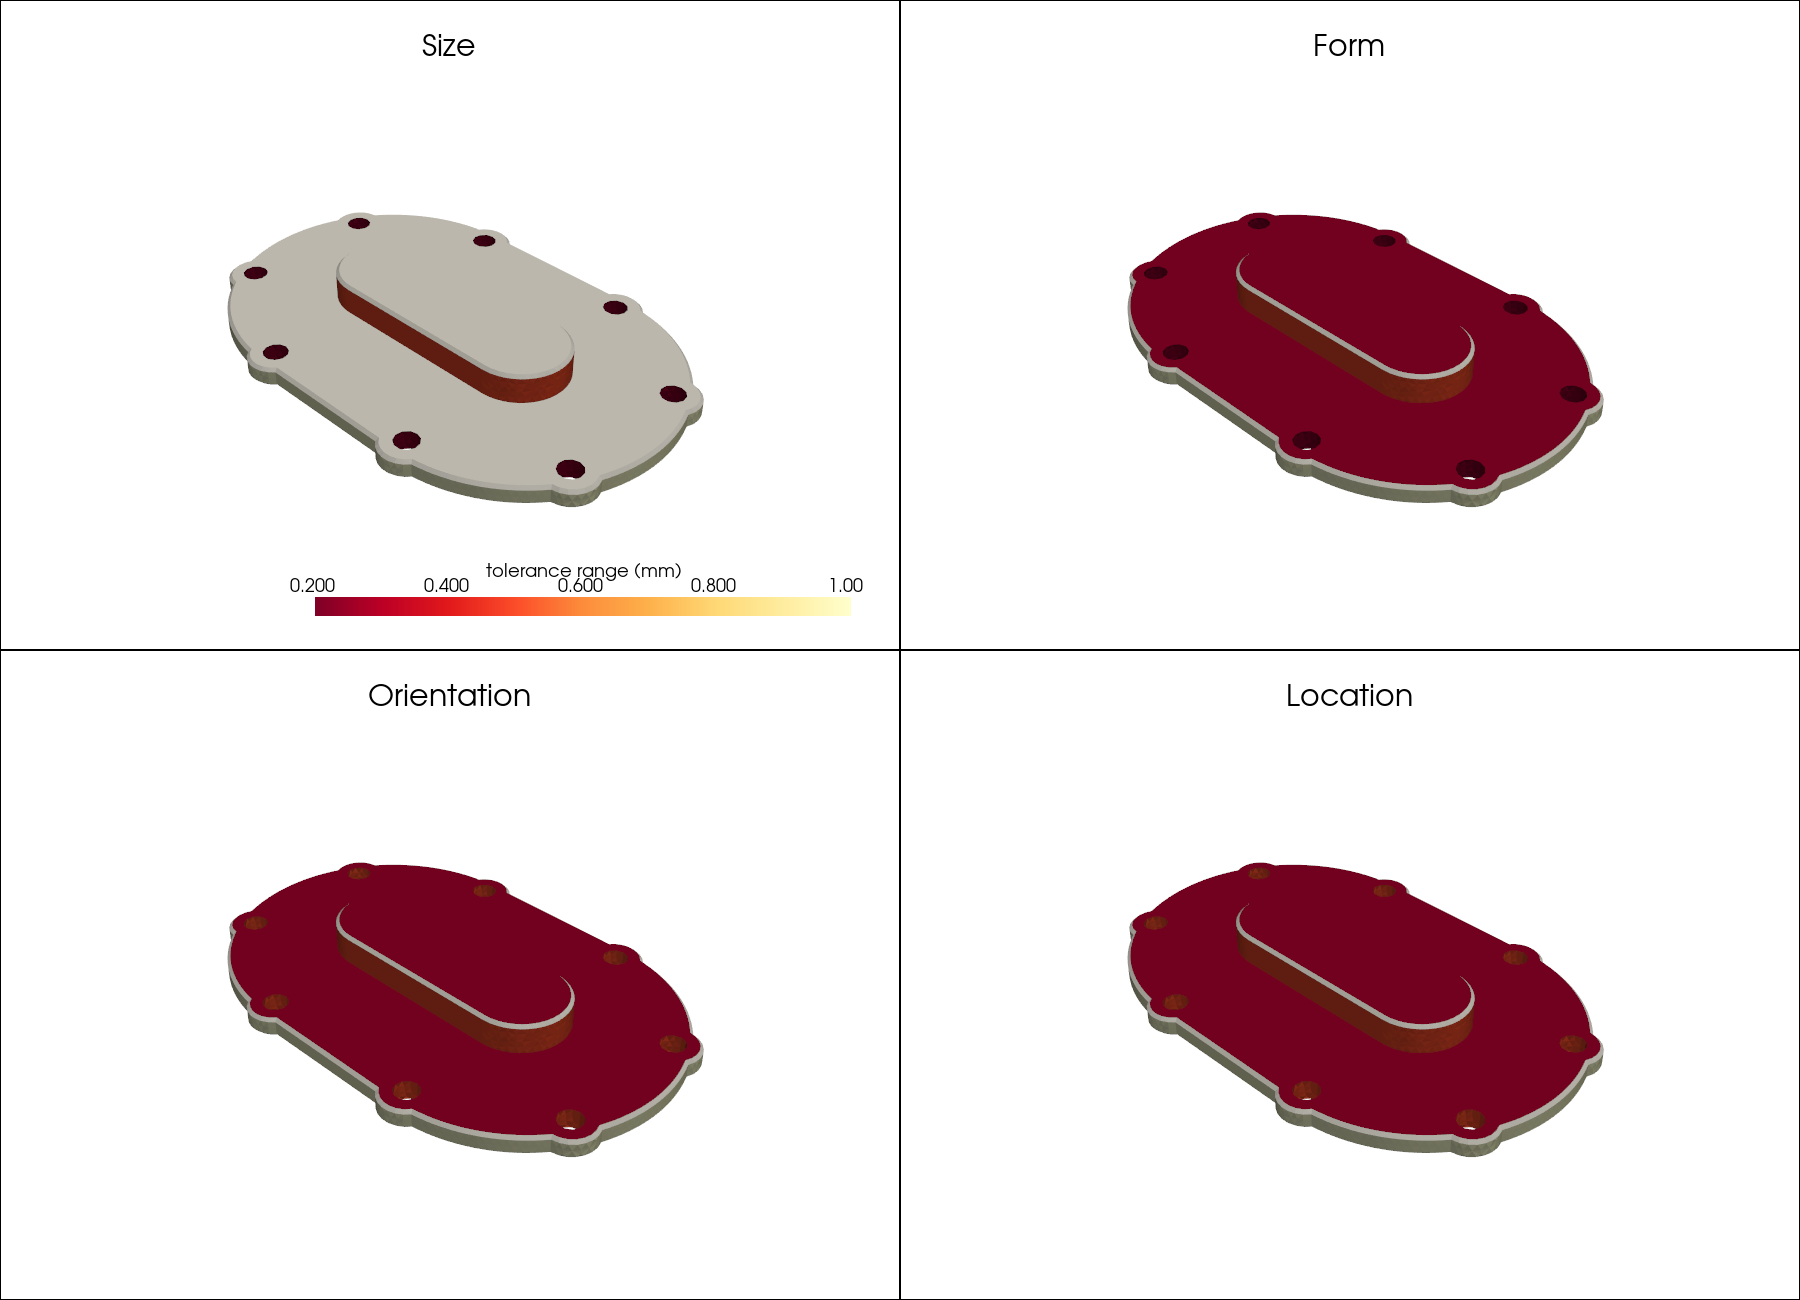

In [7]:
gdt_classes = ['size', 'form', 'orientation', 'location']

# One color scale across all four panels. Autoscaling each subplot independently
# makes the same color mean a different tolerance in each panel, so the four
# views could not be compared.
all_values = np.concatenate([np.asarray(mesh.cell_data[c], dtype=float) for c in gdt_classes])
clim = [float(np.nanmin(all_values)), float(np.nanmax(all_values))]

# Tight tolerances are the expensive ones, so they get the salient end of the
# ramp (dark red) and loose tolerances recede into pale yellow. Uncontrolled
# faces are gray, not red: that is a normal state, not an alarm, and red carries
# the "tight" meaning.
cmap = 'YlOrRd_r'
nan_color = 'lightgray'
scalar_bar_args = {'title': f'tolerance range ({linear_unit})' if linear_unit else 'tolerance range',
                 'n_labels': 5}

pl = pv.Plotter(shape=(2, 2))
for i, gdt_ctl in enumerate(gdt_classes):
    pl.subplot(i // 2, i % 2)
    pl.add_title(gdt_ctl.capitalize())
    pl.add_mesh(mesh, scalars=gdt_ctl, cmap=cmap, clim=clim,
                nan_color=nan_color, scalar_bar_args=scalar_bar_args)
pl.link_views()

print(f'shared color scale: {clim[0]:g} to {clim[1]:g} {linear_unit}'.rstrip())
print(f'gray = not controlled in that class (normal, not an error)')

qifkit.show(pl, fallback_png='01-tolerance-tightness.png')